# Where cluster GPUs sit idle: utilization, over-requesting and fragmentation

GPU clusters are expensive, and a GPU can sit idle in three different ways: a task holds it but does little work
with it, a task asks for more GPU memory or compute than it needs, or free GPUs are scattered across machines so
that a large job cannot use them. This notebook measures all three in the Alibaba PAI GPU trace of 2020, with
explicit caveats where the trace only gives a partial view.

- Data: the dataset [alibaba-gpu-trace-2020](https://www.kaggle.com/datasets/swapnilshukla007/alibaba-gpu-trace-2020), a CC BY 4.0 copy of [cluster-trace-gpu-v2020](https://github.com/alibaba/clusterdata/tree/master/cluster-trace-gpu-v2020) (Weng et al., NSDI 2022)
- Run time: 1 to 2 minutes on a Kaggle CPU notebook, no GPU needed; memory stays well inside Kaggle's limit
- Part 2 of a five-part series from the KANVAS project. Live app: [kanvas.streamlit.app](https://kanvas.streamlit.app) | Code: [github.com/Swapnil007-Curious/KANVAS](https://github.com/Swapnil007-Curious/KANVAS) | Paper: link to be added

## Contents

1. Setup and loading
2. Requested versus used GPU compute
3. Which tasks waste the most GPU time
4. GPU memory: how much of the card do tasks touch?
5. How much of the cluster is allocated over time
6. Fragmentation: free GPUs that large jobs cannot use
7. What we found, limitations and next steps

## 1. Setup and loading

Three tables carry the signal: `pai_sensor_table` has one row per instance with its GPU use averaged over the
instance's life (`gpu_wrk_util`, in percent of one GPU), `pai_instance_table` gives each instance's start, end and
machine, and `pai_task_table` gives the request (`plan_gpu`, also in percent of one GPU, per instance). The joins
run in pyarrow, which handles the 60-character worker hashes with far less memory than pandas would.

In [1]:
import os
import time
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Paths. On Kaggle the defaults apply; the two environment variables let the same notebook run elsewhere.
INPUT_ROOT = Path(os.environ.get("KAGGLE_INPUT_ROOT", "/kaggle/input"))
WORKING = Path(os.environ.get("KAGGLE_WORKING", "/kaggle/working"))
WORKING.mkdir(parents=True, exist_ok=True)

# FAST = True runs a smaller version for a quick check on a small machine. Kaggle runs use the full data.
FAST = os.environ.get("KANVAS_FAST", "0") == "1"
SEED = 42  # one seed for every random choice in the notebook

# Okabe-Ito colours, chosen so the series stay distinct for the common forms of colour blindness.
BLUE, ORANGE, GREEN, VERMILLION, PURPLE, SKY, YELLOW, BLACK = (
    "#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000")
PALETTE = [BLUE, ORANGE, GREEN, VERMILLION, PURPLE, SKY, BLACK]
SEQUENTIAL_CMAP = "cividis"  # one perceptually uniform ramp for heatmaps

mpl.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
    "axes.prop_cycle": mpl.cycler(color=PALETTE), "legend.frameon": False,
})
np.random.seed(SEED)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)


def find_data_dir(required, root=INPUT_ROOT, max_depth=4):
    """Return the first folder under ``root`` that contains every file in ``required``.

    Kaggle mounts attached datasets under /kaggle/input, and the exact sub-path has changed over the
    years, so the notebook searches for the files instead of hard-coding one layout.
    """
    root = Path(root)
    for dirpath, dirnames, filenames in os.walk(root):
        depth = len(Path(dirpath).relative_to(root).parts)
        if all(name in filenames for name in required):
            return Path(dirpath)
        if depth >= max_depth:
            dirnames[:] = []
    raise FileNotFoundError(
        f"Could not find {list(required)} under {root}. Attach the dataset 'alibaba-gpu-trace-2020' "
        "(Add Input > Datasets) and run again.")


def save_cover(draw, path=None):
    """Draw a 1280x720 cover image with ``draw(ax)`` and save it as cover.png in the working folder."""
    path = WORKING / "cover.png" if path is None else path
    fig, ax = plt.subplots(figsize=(12.8, 7.2), dpi=100)
    draw(ax)
    fig.tight_layout()
    fig.savefig(path, dpi=100)
    plt.close(fig)
    return path


print(f"pandas {pd.__version__}, numpy {np.__version__}, matplotlib {mpl.__version__}; FAST = {FAST}")

pandas 3.0.6, numpy 2.4.6, matplotlib 3.11.2; FAST = False


In [2]:
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.csv as pacsv

DATA_DIR = find_data_dir(["pai_sensor_table.csv", "pai_instance_table.csv", "pai_task_table.csv",
                          "pai_machine_spec.csv"])
DAY, HOUR = 86_400, 3_600
DEVICE_MEM_GB = {"T4": 16, "P100": 16, "V100": 16, "V100M32": 32}  # memory per card; MISC mixes several models
UTIL_BINS = [0, 1e-9, 10, 25, 50, 75, 100, np.inf]  # used share of the requested GPU, percent
UTIL_LABELS = ["0%", "0-10%", "10-25%", "25-50%", "50-75%", "75-100%", ">100%"]
WHOLE_REQUESTS = [1, 2, 4, 8]  # whole-GPU request sizes for the fragmentation check
MIN_TASKS = 2_000  # smallest group shown in per-role charts


def read_arrow(name, columns, float_cols=(), dict_cols=()):
    """Read selected columns of a trace CSV as a pyarrow Table (empty strings become nulls)."""
    opts = pacsv.ConvertOptions(include_columns=list(columns), strings_can_be_null=True,
                                column_types={**{c: pa.float64() for c in float_cols},
                                              **{c: pa.dictionary(pa.int32(), pa.string()) for c in dict_cols}})
    return pacsv.read_csv(DATA_DIR / name, convert_options=opts)


t0 = time.perf_counter()
task_tbl = read_arrow("pai_task_table.csv", ["job_name", "task_name", "plan_gpu", "gpu_type", "inst_num"],
                      ["plan_gpu", "inst_num"])
inst_tbl = read_arrow("pai_instance_table.csv", ["job_name", "task_name", "worker_name", "status", "start_time",
                                                 "end_time", "machine"], ["start_time", "end_time"])
sensor_tbl = read_arrow("pai_sensor_table.csv", ["worker_name", "gpu_wrk_util", "avg_gpu_wrk_mem", "max_gpu_wrk_mem"],
                        ["gpu_wrk_util", "avg_gpu_wrk_mem", "max_gpu_wrk_mem"])
spec = pd.read_csv(DATA_DIR / "pai_machine_spec.csv")
print(f"loaded in {time.perf_counter() - t0:.0f} s: {task_tbl.num_rows:,} tasks, {inst_tbl.num_rows:,} instances, "
      f"{sensor_tbl.num_rows:,} sensor rows, {len(spec):,} machines")

loaded in 3 s: 1,261,050 tasks, 7,522,002 instances, 3,033,232 sensor rows, 1,897 machines


In [3]:
def instance_frame(inst_tbl, task_tbl, sensor_tbl):
    """One row per instance with its request (from the task) and, where present, its sensor readings."""
    joined = (inst_tbl.join(task_tbl, keys=["job_name", "task_name"], join_type="left outer")
              .join(sensor_tbl, keys="worker_name", join_type="left outer"))
    joined = joined.drop_columns(["job_name", "worker_name"])
    df = joined.to_pandas(strings_to_categorical=True)
    df["duration"] = df["end_time"] - df["start_time"]
    df["has_sensor"] = df["gpu_wrk_util"].notna()
    return df


inst = instance_frame(inst_tbl, task_tbl, sensor_tbl)
del inst_tbl, sensor_tbl
print(f"{len(inst):,} instances; {inst['has_sensor'].mean():.1%} have a sensor row; "
      f"memory {inst.memory_usage(deep=True).sum() / 1e9:.2f} GB")
inst.groupby("status", observed=True)["has_sensor"].mean().rename("share with a sensor row").round(3).to_frame().T

7,522,002 instances; 40.2% have a sensor row; memory 0.53 GB


status,Terminated,Failed,Running,Interrupted,Waiting,Ready
share with a sensor row,0.425,0.446,0.332,0.465,0.0,0.0


Sensor coverage is about 42 to 47% for each finished status (Terminated, Failed, Interrupted), so the sensor rows
cover failed and successful runs alike. Instances that never started (Waiting, Ready)
have none.

## 2. Requested versus used GPU compute

For an instance with a sensor row and a known run time, the requested GPU time is `plan_gpu / 100 x duration`
and the used GPU time is `gpu_wrk_util / 100 x duration`. Their ratio says how much of what was reserved did work.
`gpu_wrk_util` is averaged over the instance's whole life, so start-up and data loading count as idle time, which
is how the cluster experiences it.

instances in the sample: 2,016,601
requested GPU-hours: 2,266,602; used GPU-hours: 842,842; used share of requested GPU time: 37.2%
instances that used no GPU at all: 18.0% of instances, holding 5.2% of requested GPU-hours
median used share per instance: 10.6%


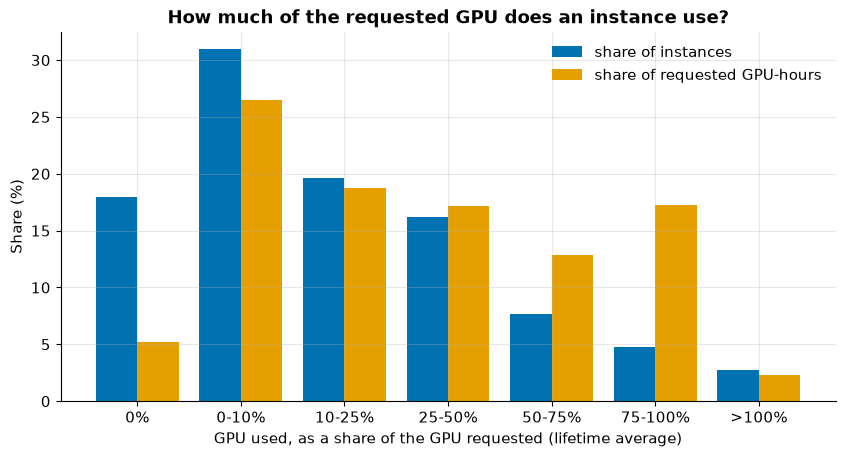

In [4]:
def usage_sample(inst):
    """GPU instances with a sensor row and a positive run time, with requested and used GPU-hours."""
    u = inst[inst["has_sensor"] & (inst["plan_gpu"] > 0) & (inst["duration"] > 0)].copy()
    u["req_gpu_h"] = u["plan_gpu"] / 100 * u["duration"] / HOUR
    u["used_gpu_h"] = u["gpu_wrk_util"] / 100 * u["duration"] / HOUR
    u["used_share"] = u["gpu_wrk_util"] / u["plan_gpu"] * 100
    u["util_bin"] = pd.cut(u["used_share"], UTIL_BINS, labels=UTIL_LABELS, right=True, include_lowest=True)
    return u


def plot_used_share(ax, u):
    """Share of instances and share of requested GPU-hours in each used-share bin."""
    by_count = u["util_bin"].value_counts(normalize=True).reindex(UTIL_LABELS) * 100
    by_time = u.groupby("util_bin", observed=False)["req_gpu_h"].sum().reindex(UTIL_LABELS)
    by_time = by_time / by_time.sum() * 100
    x = np.arange(len(UTIL_LABELS))
    ax.bar(x - 0.2, by_count, 0.4, color=BLUE, label="share of instances")
    ax.bar(x + 0.2, by_time, 0.4, color=ORANGE, label="share of requested GPU-hours")
    ax.set_xticks(x, UTIL_LABELS)
    ax.set_title("How much of the requested GPU does an instance use?")
    ax.set_xlabel("GPU used, as a share of the GPU requested (lifetime average)")
    ax.set_ylabel("Share (%)")
    ax.legend()


u = usage_sample(inst)
req_total, used_total = u["req_gpu_h"].sum(), u["used_gpu_h"].sum()
print(f"instances in the sample: {len(u):,}")
print(f"requested GPU-hours: {req_total:,.0f}; used GPU-hours: {used_total:,.0f}; "
      f"used share of requested GPU time: {used_total / req_total:.1%}")
print(f"instances that used no GPU at all: {(u['gpu_wrk_util'] == 0).mean():.1%} of instances, "
      f"holding {u.loc[u['gpu_wrk_util'] == 0, 'req_gpu_h'].sum() / req_total:.1%} of requested GPU-hours")
print(f"median used share per instance: {u['used_share'].median():.1f}%")
fig, ax = plt.subplots(figsize=(10, 4.8))
plot_used_share(ax, u)
plt.show()

Takeaway: weighted by reserved GPU time, instances use 37% of the GPU compute they request (842,842 of 2,266,602
GPU-hours). The median instance uses 11% of its request, and 18% of instances never touch the GPU, although those
hold only 5% of the reserved GPU-hours.

## 3. Which tasks waste the most GPU time

,instances,req_gpu_h,used_gpu_h,used_share,idle_gpu_h,share_of_all_idle
task_name,,,,,,
worker,1553453,1408198.0,454019.0,0.322,954179.0,0.670
PyTorchWorker,102195,546644.0,318955.0,0.583,227689.0,0.160
tensorflow,325424,294036.0,67534.0,0.230,226502.0,0.159
evaluator,8693,1272.0,209.0,0.164,1064.0,0.001
xComputeWorker,18621,1943.0,1516.0,0.780,427.0,0.000
ps,3242,239.0,2.0,0.008,237.0,0.000
OssToVolumeWorker,2395,4.0,0.0,0.000,4.0,0.000


,instances,req_gpu_h,used_gpu_h,used_share,idle_gpu_h,share_of_all_idle
gpu_type,,,,,,
MISC,1218773,1054708.0,313257.0,0.297,741451.0,0.521
P100,291377,525767.0,206708.0,0.393,319059.0,0.224
T4,447280,263252.0,86878.0,0.330,176374.0,0.124
V100,38306,164166.0,61087.0,0.372,103079.0,0.072
V100M32,20865,258709.0,174912.0,0.676,83797.0,0.059


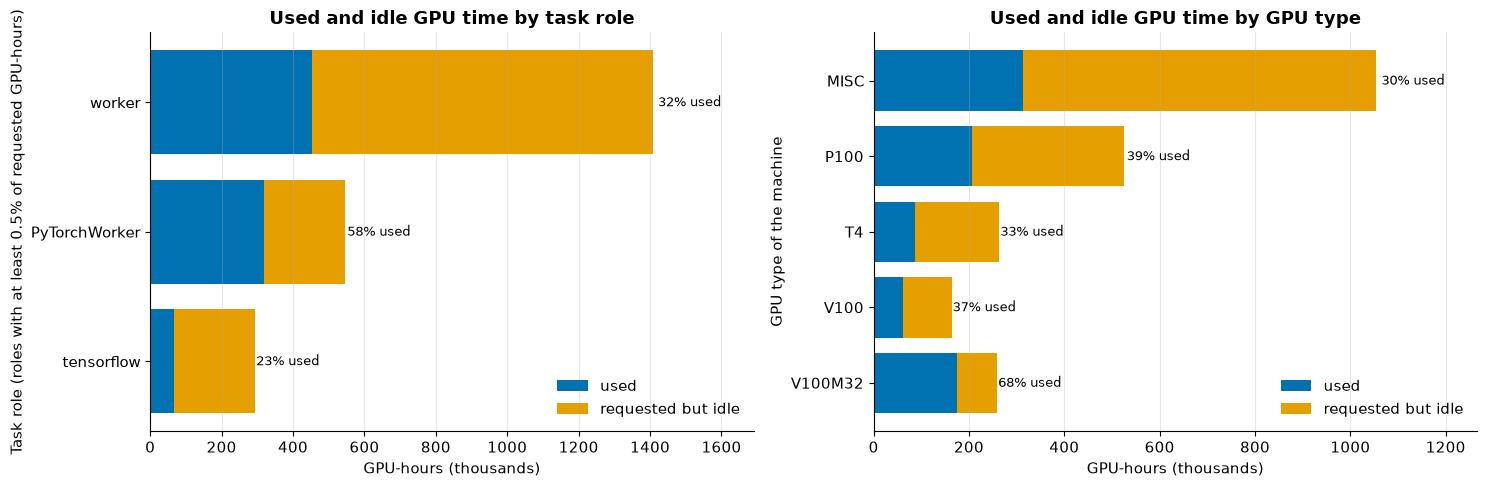

In [5]:
def usage_by(u, col, min_rows=MIN_TASKS):
    """Requested GPU-hours, used share and idle GPU-hours per value of ``col``."""
    g = u.groupby(col, observed=True).agg(instances=("req_gpu_h", "size"), req_gpu_h=("req_gpu_h", "sum"),
                                          used_gpu_h=("used_gpu_h", "sum"))
    g = g[g["instances"] >= min_rows].copy()
    g["used_share"] = g["used_gpu_h"] / g["req_gpu_h"]
    g["idle_gpu_h"] = g["req_gpu_h"] - g["used_gpu_h"]
    g["share_of_all_idle"] = g["idle_gpu_h"] / (u["req_gpu_h"].sum() - u["used_gpu_h"].sum())
    return g.sort_values("idle_gpu_h", ascending=False)


def plot_usage_by(ax, g, title, ylabel):
    """Stacked horizontal bars of used and idle GPU-hours per group."""
    g = g.iloc[::-1]
    ax.barh(g.index.astype(str), g["used_gpu_h"] / 1e3, color=BLUE, label="used")
    ax.barh(g.index.astype(str), g["idle_gpu_h"] / 1e3, left=g["used_gpu_h"] / 1e3, color=ORANGE,
            label="requested but idle")
    for i, (tot, share) in enumerate(zip(g["req_gpu_h"] / 1e3, g["used_share"])):
        ax.text(tot * 1.01, i, f"{share:.0%} used", va="center", fontsize=9)
    ax.set_xlim(0, (g["req_gpu_h"] / 1e3).max() * 1.2)
    ax.set_title(title)
    ax.set_xlabel("GPU-hours (thousands)")
    ax.set_ylabel(ylabel)
    ax.legend(loc="lower right")
    ax.grid(axis="y", visible=False)


by_role = usage_by(u, "task_name")
by_type = usage_by(u, "gpu_type")
display(by_role.round({"req_gpu_h": 0, "used_gpu_h": 0, "used_share": 3, "idle_gpu_h": 0, "share_of_all_idle": 3}))
display(by_type.round({"req_gpu_h": 0, "used_gpu_h": 0, "used_share": 3, "idle_gpu_h": 0, "share_of_all_idle": 3}))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot_usage_by(axes[0], by_role[by_role["req_gpu_h"] >= 0.005 * req_total], "Used and idle GPU time by task role",
              "Task role (roles with at least 0.5% of requested GPU-hours)")
plot_usage_by(axes[1], by_type, "Used and idle GPU time by GPU type", "GPU type of the machine")
plt.tight_layout()
plt.show()

Takeaway: the generic `worker` role holds 67% of all idle GPU-hours and uses 32% of what it reserves, while PyTorch
workers use 58%. By machine type, MISC holds half of the idle time (30% used) and V100M32 is the busiest at 68%
used, which fits its long queues in part 1.

## 4. GPU memory: how much of the card do tasks touch?

`max_gpu_wrk_mem` is the peak GPU memory of an instance in GB. Dividing by the memory of the GPU share it asked for
(card memory x `plan_gpu / 100`) gives the fraction of its memory reservation it ever used. MISC is left out because
it mixes several card models with different memory sizes.

,instances,median,below_25pct,above_100pct
gpu_type,,,,
P100,291377,0.283,0.470,0.098
T4,447280,0.094,0.750,0.001
V100,38306,0.186,0.571,0.053
V100M32,20865,0.141,0.667,0.001


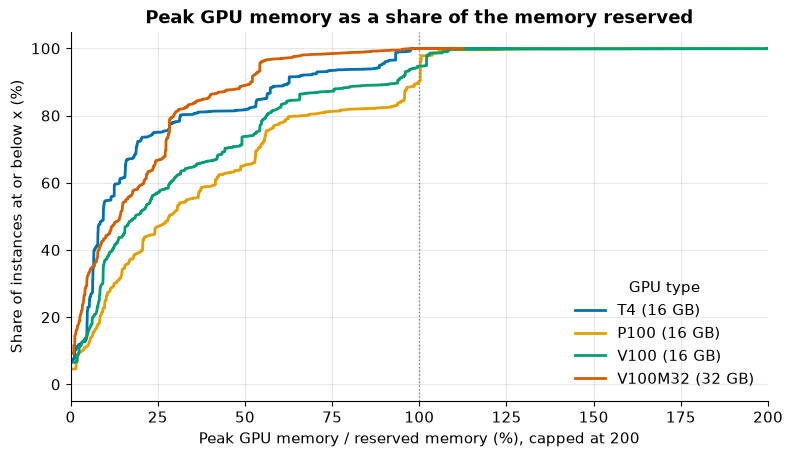

In [6]:
def memory_use(u):
    """Peak GPU memory as a share of the reserved memory, for GPU types with a known card size."""
    m = u[u["gpu_type"].astype(str).isin(DEVICE_MEM_GB)].copy()
    card = m["gpu_type"].astype(str).map(DEVICE_MEM_GB).astype(float)
    m["reserved_gb"] = card * m["plan_gpu"] / 100
    m["peak_share"] = m["max_gpu_wrk_mem"] / m["reserved_gb"]
    return m


def plot_memory_cdf(ax, m):
    """CDF of peak memory share per GPU type."""
    for gt, color in zip(DEVICE_MEM_GB, PALETTE):
        v = np.sort(m.loc[m["gpu_type"].astype(str) == gt, "peak_share"].clip(0, 2).to_numpy() * 100)
        if len(v):
            ax.plot(v, np.arange(1, len(v) + 1) / len(v) * 100, color=color, lw=2, label=f"{gt} ({DEVICE_MEM_GB[gt]} GB)")
    ax.axvline(100, color="grey", ls=":", lw=1)
    ax.set_xlim(0, 200)
    ax.set_title("Peak GPU memory as a share of the memory reserved")
    ax.set_xlabel("Peak GPU memory / reserved memory (%), capped at 200")
    ax.set_ylabel("Share of instances at or below x (%)")
    ax.legend(title="GPU type")


m = memory_use(u)
mem_tab = m.groupby(m["gpu_type"].astype(str))["peak_share"].agg(
    instances="size", median="median", below_25pct=lambda s: (s < 0.25).mean(), above_100pct=lambda s: (s > 1).mean())
display(mem_tab.round(3))
fig, ax = plt.subplots(figsize=(9, 4.8))
plot_memory_cdf(ax, m)
plt.show()

Takeaway: the median T4 instance peaks at 9% of its memory reservation and 75% of T4 instances never reach a
quarter of it. P100 instances use more (median 28%), and 10% of them go above their share, which is possible
because fractional requests share a card and memory is not partitioned by `plan_gpu`.

## 5. How much of the cluster is allocated over time

To see allocation over time, we rebuild, for every hour, which instances were running on which machine and add up
their `plan_gpu`. One caveat shapes everything below: only instances with both a start and an end time can be
placed in time, and most failed instances have no end time (the next cell counts them). The series is therefore a
lower bound on allocation, and the free capacity in section 6 is an upper bound.

In [7]:
def placeable_instances(inst):
    """GPU instances with a start, an end after it, and a machine in the spec table."""
    ok = (inst["start_time"].notna() & inst["end_time"].notna() & (inst["end_time"] > inst["start_time"])
          & (inst["plan_gpu"] > 0) & (inst["status"].astype(str) != "Running"))
    return inst.loc[ok, ["machine", "start_time", "end_time", "plan_gpu", "status"]]


def hourly_allocation(placed, spec):
    """Matrix (machines x hours) of allocated GPUs, the hour grid and the machine order (spec order)."""
    machines = pd.Index(spec["machine"].astype(str))
    mi = machines.get_indexer(placed["machine"].astype(str))
    keep = mi >= 0
    start, end = placed["start_time"].to_numpy()[keep], placed["end_time"].to_numpy()[keep]
    gpus = placed["plan_gpu"].to_numpy()[keep] / 100
    grid = np.arange(np.floor(start.min() / HOUR) * HOUR, end.max() + HOUR, HOUR)
    ks, ke = np.searchsorted(grid, start, side="left"), np.searchsorted(grid, end, side="left")
    diff = np.zeros((len(machines), len(grid) + 1))
    np.add.at(diff, (mi[keep], ks), gpus)
    np.add.at(diff, (mi[keep], ke), -gpus)
    return np.cumsum(diff, axis=1)[:, :len(grid)], grid


placed = placeable_instances(inst)
gpu_inst = inst[inst["plan_gpu"] > 0]
failed = gpu_inst["status"].astype(str) == "Failed"
print(f"GPU instances placeable in time: {len(placed):,} of {len(gpu_inst):,} ({len(placed) / len(gpu_inst):.1%})")
print(f"failed GPU instances with an end time: {(failed & gpu_inst['end_time'].notna()).sum():,} of {failed.sum():,}")
alloc, grid = hourly_allocation(placed, spec)
cap = spec["cap_gpu"].to_numpy(dtype=float)
total_alloc = alloc.sum(axis=0)
days = grid / DAY

GPU instances placeable in time: 3,743,030 of 5,881,484 (63.6%)
failed GPU instances with an end time: 75,871 of 877,336


analysis window: trace days 14.5 to 72.2 (1,387 hourly snapshots)
allocated share of installed GPUs in the window: median 39.5%, 10th to 90th percentile 29.8% to 47.2%
machine-hours where allocation exceeds capacity (fractional sharing or timestamp noise): 0.37%


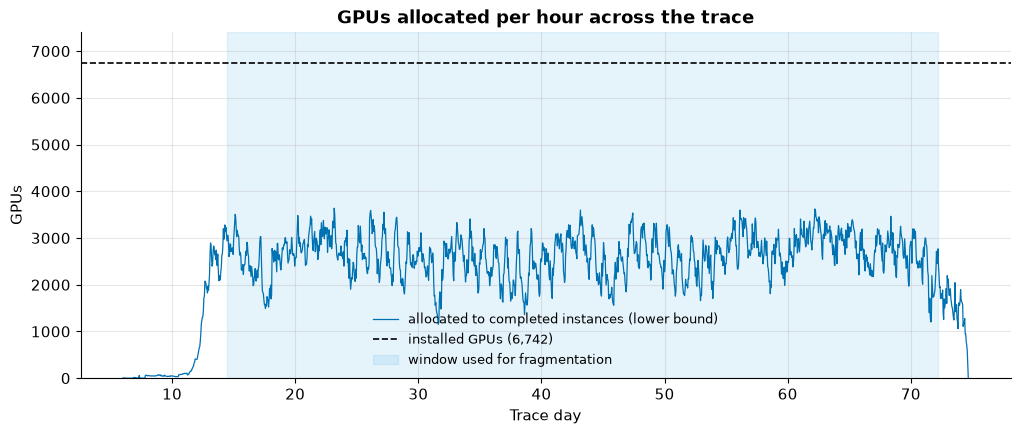

In [8]:
def steady_window(total_alloc, days, frac=0.5, pad_days=2):
    """Trace days where allocation stays near its typical level: from the first day above ``frac`` x median
    (plus a pad) to the last such day (minus a pad)."""
    level = np.median(total_alloc[total_alloc > 0])
    above = np.flatnonzero(total_alloc > frac * level)
    return days[above[0]] + pad_days, days[above[-1]] - pad_days


def plot_allocation(ax, days, total_alloc, capacity, window):
    """Allocated GPUs per hour against installed capacity, with the analysis window shaded."""
    ax.plot(days, total_alloc, color=BLUE, lw=0.9, label="allocated to completed instances (lower bound)")
    ax.axhline(capacity, color=BLACK, ls="--", lw=1.2, label=f"installed GPUs ({capacity:,.0f})")
    ax.axvspan(*window, color=SKY, alpha=0.15, label="window used for fragmentation")
    ax.set_ylim(0, capacity * 1.1)
    ax.set_title("GPUs allocated per hour across the trace")
    ax.set_xlabel("Trace day")
    ax.set_ylabel("GPUs")
    ax.legend(loc="lower center", fontsize=9)


window = steady_window(total_alloc, days)
in_win = (days >= window[0]) & (days <= window[1])
share = total_alloc[in_win] / cap.sum()
print(f"analysis window: trace days {window[0]:.1f} to {window[1]:.1f} ({in_win.sum():,} hourly snapshots)")
print(f"allocated share of installed GPUs in the window: median {np.median(share):.1%}, "
      f"10th to 90th percentile {np.percentile(share, 10):.1%} to {np.percentile(share, 90):.1%}")
over = (alloc[:, in_win] > cap[:, None] + 1e-9)[cap > 0]
print(f"machine-hours where allocation exceeds capacity (fractional sharing or timestamp noise): {over.mean():.2%}")
fig, ax = plt.subplots(figsize=(12, 4.5))
plot_allocation(ax, days, total_alloc, cap.sum(), window)
plt.show()

Takeaway: in the steady stretch (trace days 14.5 to 72.2) the median hour has 39.5% of the installed GPUs allocated
to instances that can be placed in time, with a 10th to 90th percentile range of 30% to 47%. Since 91% of failed GPU
instances have no end time, the true allocation is higher by an amount the trace does not reveal.

## 6. Fragmentation: free GPUs that large jobs cannot use

A distributed training instance that needs 8 GPUs must find 8 free GPUs on one machine. For each hour in the window
we take the free GPUs on every machine (capacity minus allocation, floored at zero, whole GPUs only) and ask: of all
free GPUs, how many could actually host requests of 1, 2, 4 or 8 GPUs? The gap between the two is fragmentation.

,idle,partly used,full
2-GPU machines,46.4,33.8,19.8
8-GPU machines,28.5,65.0,6.5


,mean free GPUs per hour,usable by 1-GPU requests,usable by 2-GPU requests,usable by 4-GPU requests,usable by 8-GPU requests
all 8-GPU machines,2391.453,1.0,0.928,0.771,0.495
MISC,921.927,1.0,0.853,0.542,0.058
V100,636.774,1.0,0.964,0.877,0.673
V100M32,832.751,1.0,0.985,0.944,0.843


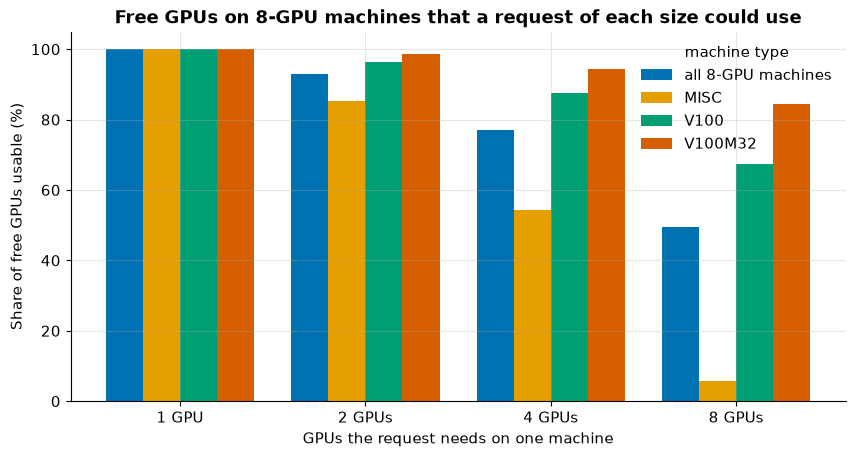

In [9]:
def machine_states(alloc, cap, mask, size):
    """Share of machine-hours that are idle, partly used or full, for machines with ``size`` GPUs."""
    a = alloc[cap == size][:, mask]
    free = np.clip(size - a, 0, None)
    idle, full = a < 1e-9, free < 1e-9
    return {"idle": idle.mean(), "partly used": (~idle & ~full).mean(), "full": full.mean()}


def placeable_share(alloc, cap, mask, sizes=WHOLE_REQUESTS, machine_size=8):
    """Mean free whole GPUs per hour and the share of them usable by requests of each size."""
    a = alloc[cap == machine_size][:, mask]
    free_whole = np.floor(np.clip(machine_size - a, 0, None) + 1e-9)
    total = free_whole.sum(axis=0)
    out = {"mean free GPUs per hour": total.mean()}
    for g in sizes:
        usable = (np.floor(free_whole / g) * g).sum(axis=0)
        out[f"usable by {g}-GPU requests"] = usable.sum() / total.sum()
    return out


def plot_placeable(ax, frag_by_type):
    """Grouped bars: share of free GPUs usable by 1-, 2-, 4- and 8-GPU requests, per 8-GPU machine type."""
    x = np.arange(len(WHOLE_REQUESTS))
    width = 0.8 / len(frag_by_type)
    for i, (name, row) in enumerate(frag_by_type.iterrows()):
        vals = [row[f"usable by {g}-GPU requests"] * 100 for g in WHOLE_REQUESTS]
        ax.bar(x + (i - (len(frag_by_type) - 1) / 2) * width, vals, width, color=PALETTE[i], label=name)
    ax.set_xticks(x, [f"{g} GPU" + ("s" if g > 1 else "") for g in WHOLE_REQUESTS])
    ax.set_ylim(0, 105)
    ax.set_title("Free GPUs on 8-GPU machines that a request of each size could use")
    ax.set_xlabel("GPUs the request needs on one machine")
    ax.set_ylabel("Share of free GPUs usable (%)")
    ax.legend(title="machine type")


states = pd.DataFrame({f"{s}-GPU machines": machine_states(alloc, cap, in_win, s) for s in (2, 8)}).T
display((states * 100).round(1))
frag_all = placeable_share(alloc, cap, in_win)
gpu_type = spec["gpu_type"].astype(str).to_numpy()
frag_by_type = {"all 8-GPU machines": frag_all}
for gt in ["MISC", "V100", "V100M32"]:
    sel = gpu_type == gt
    frag_by_type[gt] = placeable_share(alloc[sel], cap[sel], in_win)
frag_by_type = pd.DataFrame(frag_by_type).T
display(frag_by_type.round(3))
fig, ax = plt.subplots(figsize=(10, 4.8))
plot_placeable(ax, frag_by_type)
plt.show()

In [10]:
def idle_machines(alloc, cap, mask, gpu_type, kind):
    """Share of hours with at least one fully idle 8-GPU machine of a type, and the mean count per hour."""
    sel = (gpu_type == kind) & (cap == 8)
    idle = alloc[sel][:, mask] < 1e-9
    return idle.any(axis=0).mean(), idle.sum(axis=0).mean(), int(sel.sum())


for kind in ["MISC", "V100", "V100M32"]:
    share_hours, mean_idle, n = idle_machines(alloc, cap, in_win, gpu_type, kind)
    print(f"{kind}: at least one fully idle machine in {share_hours:.0%} of hours; "
          f"on average {mean_idle:.0f} of {n} machines fully idle")

MISC: at least one fully idle machine in 100% of hours; on average 7 of 280 machines fully idle
V100: at least one fully idle machine in 100% of hours; on average 54 of 104 machines fully idle
V100M32: at least one fully idle machine in 100% of hours; on average 88 of 135 machines fully idle


Takeaway: on 8-GPU machines an average of 2,391 GPUs are free each hour, but only 49.5% of them sit on fully idle
machines that an 8-GPU request could use. On MISC machines the figure is 5.8%, because their free GPUs are almost
always spread over partly used machines; V100M32 machines are the opposite at 84%.

The reconstruction also has a puzzle in it. In an average hour, 54 of the 104 V100 machines and 88 of the 135
V100M32 machines show no allocated instance at all, yet part 1 found tasks on those machines waiting the longest.
Either instances the trace cannot place in time (failed ones without an end time, and instances that never record a
start) occupy those machines, or capacity is split into pools (quotas, reservations) that the trace does not
record. Either way the V100 bars above overstate how much an 8-GPU job could really use. The MISC result, where
only 7 of 280 machines are idle in an average hour, is the most trustworthy of the four, and adding the missing load
can only make fragmentation worse.

In [11]:
save_cover(lambda ax: plot_placeable(ax, frag_by_type))
print("saved cover.png (fragmentation on 8-GPU machines)")

saved cover.png (fragmentation on 8-GPU machines)


## 7. What we found

- Weighted by reserved GPU time, instances use 37% of the GPU compute they request, measured from the lifetime
  average `gpu_wrk_util` of 2.0 million instances with sensor rows; the median instance uses 11%.
- The generic `worker` role holds two thirds of the idle reserved GPU-hours.
- Peak GPU memory is far below the reservation: the median T4 instance peaks at 9% of its share.
- Counting only instances that can be placed in time, 39.5% of the installed GPUs are allocated in the median hour.
- On 8-GPU machines about half of the free GPUs cannot host an 8-GPU request, and on MISC machines 94% cannot. The
  V100 figures are less reliable, because about half of those machines show no placeable load at all.

### Limitations

- `gpu_wrk_util` and the memory columns are lifetime averages or peaks, so bursty jobs look less busy than they are
  at their peak, and short spikes are invisible.
- Sensor rows cover about 42 to 47% of finished instances; the shares above describe that sample.
- Most failed instances lack an end time, so the hourly allocation is a lower bound and free capacity an upper bound.
- Fractional requests (a quarter of a GPU) share a card, so "free whole GPUs" ignores leftover fractions.

### Ideas to try

- Repeat the used-share analysis per user to see whether a few users hold most of the idle reservations.
- Simulate a scheduler that packs fractional requests onto fewer cards and measure how many whole machines it frees.
- Estimate the durations of failed instances from `pai_task_table` and rerun the allocation with them.

### The series

1. [Alibaba PAI GPU trace 2020: a complete EDA](https://www.kaggle.com/code/swapnilshukla007/alibaba-pai-gpu-trace-2020-a-complete-eda)
2. Where cluster GPUs sit idle: utilization, over-requesting and fragmentation (this notebook)
3. [Predicting GPU task failure: a LightGBM baseline explained with SHAP](https://www.kaggle.com/code/swapnilshukla007/predicting-gpu-task-failure-lightgbm-and-shap)
4. [Kolmogorov-Arnold additive models from scratch: B-spline edge functions in PyTorch](https://www.kaggle.com/code/swapnilshukla007/kolmogorov-arnold-additive-models-from-scratch)
5. [Reading the splines: KAAM shape functions vs SHAP on the same tasks](https://www.kaggle.com/code/swapnilshukla007/reading-the-splines-kaam-curves-vs-shap)

If something here is wrong or unclear, a comment helps more than anything; an upvote helps others find it.